### Run in terminal

In [3]:
%pip install pandas numpy matplotlib seaborn openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Read name sheets from ridfatal.xlsx file

In [3]:
import pandas as pd
import os

file_path = "C:/Users/micha/OneDrive/Desktop/magda/VSC/Project_15/data/raw/data_hse/ridfatal.xlsx"

# List all sheets
excel = pd.ExcelFile(file_path)

print(excel.sheet_names)

['Contents', 'Guidance', 'Notes', 'Table 1', 'Table 2', 'Table 3', 'Table 4', 'Table 5']


### Read all sheets

### Check first 20 rows of each sheet

Why `header=None`?

Official statistical spreadsheets often include titles, footnotes, sources, and comments before the actual table. We do not want pandas to automatically misidentify a row as the header.

Once we have examined the spreadsheets, we will select the appropriate tables, remove any unnecessary rows, and assign clear, readable names to the columns.

In [6]:
# Read all sheets
sheets = pd.read_excel(
    file_path,
    sheet_name=None,
    header=None
)

# Check first 20 rows of each sheet
for sheet_name, df in sheets.items():
    print("\nSHEET:", sheet_name)
    display(df.head(20))


SHEET: Contents


,0
0,RIDFATAL: Work-related fatal injuries reportab...
1,"Source: Reporting of Injuries, Diseases and Da..."
2,Contents
3,Guidance on using the spreadsheet
4,Notes - General notes applicable to all tables
5,Table 1: Work-related fatal injuries to worker...
6,Table 2: Work-related fatal injuries to member...
7,Table 3: Work-related fatal injuries to worker...
8,Table 4: Work-related fatal injuries to worker...
9,Table 5: Work-related fatal injuries to worker...



SHEET: Guidance


,0
0,Guidance on using the spreadsheet
1,This worksheet contains a short paragraph of t...
2,Contents
3,Default view
4,"By default, tables 1 and 3-5 are filtered to s..."
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN



SHEET: Notes


,0,1
0,General notes applicable to all tables,NaN
1,This worksheet contains important background n...,NaN
2,Contents,NaN
3,Background notes on the data,NaN
4,Note code,Note text
5,Note a,Statistics presented in these tables are for w...
6,Note b,Table 1 and Tables 3-5 present annual reportab...
7,Note c,Table 2 presents the number of annual reportab...
8,Note d,Rates of injury: Differences in the size of th...
9,Note e,For more information on statistics of work-rel...


... (6 outputs left out)


SHEET: Table 4


,0,1,2,3,4,5,6,7,8
0,Table 4: Work-related fatal injuries to worker...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Contents,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,This worksheet contains one table. Some cells ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Filters are active in row 8 and may hide some ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,To view data for other combinations of year an...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Some cells in the table are blank due to there...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,"Some shorthand is used in this table, [z] = no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Year\n[Note 1] [Note 14],Sort code [Note 18],Age group,Number of fatal injuries to workers [Note 3],Number of fatal injuries to\nemployees \n,Number of fatal injuries to\nself-employed \n,"Rate of fatal injury per 100,000 workers\n[Not...","Rate of fatal injury per 100,000 employees \n[...","Rate of fatal injury per 100,000 self-employed..."
8,2021/22 [Note 10] [Note 11],0,All,123,83,40,0.38,0.3,0.86
9,2021/22 [Note 10] [Note 11],1,Under 16,0,0,0,0,0,0



SHEET: Table 5


,0,1,2,3,4,5,6,7,8,9,10
0,Table 5: Work-related fatal injuries to worker...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Contents,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,This worksheet contains one table. Some cells ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Filters are active in row 8 and may hide some ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"To view data for other combinations of year, c...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Some cells in the table are blank due to there...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,"Some shorthand is used in this table, [z] = no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Year\n[Note 1] [Note 14],Sort code [Note 18],Area code\n[Note 12],Area,Area Type [Note 13],Number of fatal injuries to workers [Note 3],Number of fatal injuries to\nemployees \n,Number of fatal injuries to\nself-employed \n,"Rate of fatal injury per 100,000 workers\n[Not...","Rate of fatal injury per 100,000 employees \n[...","Rate of fatal injury per 100,000 self-employed..."
8,2021/22 [Note 10] [Note 11],0,K03000001,Great Britain,Country,123,83,40,0.38,0.3,0.86
9,2021/22 [Note 10] [Note 11],1,E92000001,England,Country,103,69,34,0.37,0.29,0.83


### The export reads the underlying worksheet values, not Excel's displayed filters or formatting, and leaves ridfatal.xlsx unchanged.

In [10]:
from pathlib import Path
import re

project_root = Path(file_path).resolve().parents[3]
output_dir = project_root / "data" / "processed" / "ridfatal_csv"
output_dir.mkdir(parents=True, exist_ok=True)

for sheet_name, raw_sheet in sheets.items():
    raw_sheet = raw_sheet.copy()

    if sheet_name.startswith("Table "):
        first_column = raw_sheet.iloc[:, 0].astype("string").str.strip()
        if sheet_name == "Table 2":
            header_matches = raw_sheet.index[
                first_column.str.startswith("Main Industry SIC", na=False)
            ].tolist()
        else:
            header_matches = raw_sheet.index[
                first_column.str.startswith("Year", na=False)
            ].tolist()

        if len(header_matches) != 1:
            raise ValueError(
                f"Expected one header row in {sheet_name}, found {len(header_matches)}"
            )

        header_row = header_matches[0]
        headers = []
        for column_number, value in enumerate(raw_sheet.iloc[header_row], start=1):
            header = "" if pd.isna(value) else str(value)
            header = re.sub(r"\s*\[Note[^\]]*\]", "", header, flags=re.IGNORECASE)
            header = re.sub(r"\s+", " ", header).strip()
            headers.append(header or f"column_{column_number}")

        seen_headers = {}
        unique_headers = []
        for header in headers:
            seen_headers[header] = seen_headers.get(header, 0) + 1
            suffix = f"_{seen_headers[header]}" if seen_headers[header] > 1 else ""
            unique_headers.append(f"{header}{suffix}")

        export_table = raw_sheet.iloc[header_row + 1 :].copy()
        export_table.columns = unique_headers
        export_table = export_table.dropna(how="all")
    else:
        # These tabs are explanatory text rather than a single structured table.
        export_table = raw_sheet.copy()
        export_table.columns = [
            f"column_{column_number}"
            for column_number in range(1, len(export_table.columns) + 1)
        ]

    output_path = output_dir / f"ridfatal_{sheet_name.lower().replace(' ', '_')}.csv"
    export_table.to_csv(output_path, index=False, encoding="utf-8-sig")
    print(f"Saved {len(export_table)} rows: {output_path}")

Saved 12 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_contents.csv
Saved 24 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_guidance.csv
Saved 34 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_notes.csv
Saved 90 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_table_1.csv
Saved 14 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_table_2.csv
Saved 102 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_table_3.csv
Saved 66 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_table_4.csv
Saved 90 rows: C:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\processed\ridfatal_csv\ridfatal_table_5.csv


### Data cleaning

In [7]:
# Example cleaning operations
df.columns = df.columns.astype(str).str.strip()

# Remove completely empty rows and columns
df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

# Check missing values
print(df.isna().sum())

# Check duplicates
print("Duplicates:", df.duplicated().sum())

# Check data types
print(df.dtypes)

0      0
1      7
2     19
3      7
4     19
5      7
6      7
7      7
8      7
9      7
10     7
dtype: int64
Duplicates: 0
0        str
1     object
2        str
3        str
4        str
5     object
6     object
7     object
8     object
9     object
10    object
dtype: object


#### Read-only quality checks for Table 3
#### The raw workbook and the `sheets` DataFrames are not modified.

#####  
read-only quality check for the fatal-injuries workbook. It prepares the Table 3 data for checks, then reports potential issues; it does not save changes to the workbook or the source data.

It finds Table 3’s header row by looking for a first-column value that starts with Year. It copies the rows below that header into a separate DataFrame called table, gives its six columns readable names, and removes fully empty rows.
It searches Tables 1–5 for cells whose value is exactly Unknown. Those may be valid categories, so it reports them for review rather than treating them as errors.
It checks Table 3’s three injury-count columns for numeric values stored as text.
It checks for exact duplicate rows and duplicate year + sort_code combinations.
For each year, it sums the accident-kind categories and compares the sums with the All accident kinds total.
It reads the year suffixes: no suffix is labeled historical, r revised, and p preliminary. It checks whether the latest year is marked preliminary.
In the current workbook, the checks find six Unknown age-group entries in Table 4; Table 3 has no duplicate rows, its category sums match the totals for all six years, and the year suffixes are recognized. The year-label check interprets the suffixes in the data; it doesn’t independently verify them against HSE documentation.

In [8]:
# Read-only quality checks for Table 3 (fatal injuries by kind of accident)
# The raw workbook and the `sheets` DataFrames are not modified.
raw_table = sheets["Table 3"]
header_matches = raw_table.index[
    raw_table.iloc[:, 0].astype("string").str.strip().str.startswith("Year", na=False)
].tolist()
if len(header_matches) != 1:
    raise ValueError(f"Expected one table header in Table 3, found {len(header_matches)}")

header_row = header_matches[0]
table = raw_table.iloc[header_row + 1 :].copy()
table.columns = ["year", "sort_code", "category", "workers", "employees", "self_employed"]
table = table.dropna(how="all")
table = table.loc[table["year"].notna() & table["category"].notna()].copy()
table["year"] = table["year"].astype("string").str.strip()
table["category"] = table["category"].astype("string").str.strip()

print(f"Checking Table 3: {len(table)} data rows")

# Report exact Unknown values in the workbook's data tables (may be valid categories).
unknown_cells = []
for sheet_name in ["Table 1", "Table 2", "Table 3", "Table 4", "Table 5"]:
    raw_sheet = sheets[sheet_name]
    unknown_mask = raw_sheet.astype("string").apply(
        lambda column: column.str.strip().str.casefold().eq("unknown")
    ).fillna(False)
    locations = unknown_mask.stack()
    locations = locations[locations].index.tolist()
    if locations:
        unknown_cells.extend((sheet_name, row, column) for row, column in locations)
if unknown_cells:
    print(f"REVIEW Exact 'Unknown' cells ({len(unknown_cells)}): {unknown_cells[:10]}")
else:
    print("PASS No exact 'Unknown' values in Table 1-5")

# Check that the count columns were imported as numbers, not numeric strings.
count_columns = ["workers", "employees", "self_employed"]
numeric_text = {}
for column in count_columns:
    mask = table[column].map(
        lambda value: isinstance(value, str)
        and value.strip() != ""
        and pd.notna(pd.to_numeric(value, errors="coerce"))
    )
    if mask.any():
        numeric_text[column] = table.loc[mask, column].head(5).tolist()
if numeric_text:
    print("FAIL Numeric values stored as text:", numeric_text)
else:
    print("PASS Count columns are not stored as numeric text")

# Check exact duplicates and the table's year + sort-code row key.
exact_duplicates = int(table.duplicated(keep=False).sum())
key_duplicates = int(table.duplicated(subset=["year", "sort_code"], keep=False).sum())
print(f"{'FAIL' if exact_duplicates else 'PASS'} Exact duplicate rows: {exact_duplicates}")
print(f"{'FAIL' if key_duplicates else 'PASS'} Duplicate year/sort-code keys: {key_duplicates}")

# Accident-kind categories are mutually exclusive in Table 3, so compare their sums to the total row.
total_mismatches = []
for year, year_rows in table.groupby("year", sort=False):
    yearly_total = year_rows[year_rows["category"].str.casefold() == "all accident kinds"]
    categories = year_rows[year_rows["category"].str.casefold() != "all accident kinds"]
    if len(yearly_total) != 1 or categories.empty:
        total_mismatches.append((year, "missing or multiple total rows"))
        continue
    for column in count_columns:
        category_sum = pd.to_numeric(categories[column], errors="coerce").sum(min_count=1)
        overall_total = pd.to_numeric(yearly_total[column], errors="coerce").iloc[0]
        if pd.isna(category_sum) or pd.isna(overall_total) or category_sum != overall_total:
            total_mismatches.append((year, column, category_sum, overall_total))
if total_mismatches:
    print("FAIL Category sums do not match overall totals:", total_mismatches[:10])
else:
    print(f"PASS Category sums match the overall total for {table['year'].nunique()} years")

# HSE marks preliminary years with 'p' and revised years with 'r'; no suffix means historical/final.
period_labels = table["year"].str.extract(
    r"(?P<period>[0-9]{4}/[0-9]{2})(?P<mark>[pr])?"
)
period_labels["label"] = period_labels["mark"].map(
    {"p": "preliminary", "r": "revised"}
).fillna("historical")
period_labels = period_labels.drop_duplicates().dropna(subset=["period"])
print("Year labels found:")
print(period_labels.to_string(index=False))
if period_labels.empty:
    print("FAIL Could not parse any year labels")
else:
    preliminary = period_labels[period_labels["label"] == "preliminary"]
    latest_period = period_labels.sort_values("period").iloc[-1]["period"]
    if len(preliminary) == 1 and preliminary.iloc[0]["period"] == latest_period:
        print("PASS The latest year is marked preliminary; revised years remain distinct")
    else:
        print("REVIEW Preliminary/revised suffixes; confirm against the source workbook notes")

Checking Table 3: 102 data rows
REVIEW Exact 'Unknown' cells (6): [('Table 4', 18, 2), ('Table 4', 29, 2), ('Table 4', 40, 2), ('Table 4', 51, 2), ('Table 4', 62, 2), ('Table 4', 73, 2)]
PASS Count columns are not stored as numeric text
PASS Exact duplicate rows: 0
PASS Duplicate year/sort-code keys: 0
PASS Category sums match the overall total for 6 years
Year labels found:
 period mark       label
2021/22 <NA>  historical
2022/23 <NA>  historical
2023/24 <NA>  historical
2024/25    r     revised
2025/26    p preliminary
PASS The latest year is marked preliminary; revised years remain distinct


Extract and Format Provisional 2025/26 Workplace Safety Data
This cell defines a robust parsing function (make_2025_26_table) to dynamically locate header rows, filter for provisional 2025/26 data (2025/26p), and clean up the relevant columns. It then processes three separate sheets (Industry, Accident Kind, and Age Group) from the Health and Safety Executive (HSE) source files, converts injury counts to numeric types, and renders them cleanly with formatted Markdown headers.

In [9]:
from IPython.display import Markdown, display


def make_2025_26_table(sheet_name, category_name):
    raw_sheet = sheets[sheet_name]
    first_column = raw_sheet.iloc[:, 0].astype("string").str.strip()
    header_matches = raw_sheet.index[
        first_column.str.startswith("Year", na=False)
    ].tolist()
    if len(header_matches) != 1:
        raise ValueError(
            f"Expected one header row in {sheet_name}, found {len(header_matches)}"
        )

    header_row = header_matches[0]
    data = raw_sheet.iloc[header_row + 1 :].copy()
    periods = data.iloc[:, 0].astype("string").str.strip()
    data = data.loc[periods.str.startswith("2025/26p", na=False)]

    if data.empty:
        raise ValueError(f"No 2025/26p rows found in {sheet_name}")

    result = data.iloc[:, [2, 3]].copy()
    result.columns = [category_name, "Fatal injuries (workers)"]
    result[category_name] = result[category_name].astype("string").str.strip()
    result["Fatal injuries (workers)"] = pd.to_numeric(
        result["Fatal injuries (workers)"], errors="coerce"
    )
    return result.dropna(subset=[category_name]).reset_index(drop=True)


industry_2025_26 = make_2025_26_table("Table 1", "Industry")
accident_kind_2025_26 = make_2025_26_table("Table 3", "Accident kind")
age_group_2025_26 = make_2025_26_table("Table 4", "Age group")

display(Markdown("### Table 1: Industry, 2025/26p"))
display(industry_2025_26)

display(Markdown("### Table 3: Accident kind, 2025/26p"))
display(accident_kind_2025_26)

display(Markdown("### Table 4: Age group, 2025/26p"))
display(age_group_2025_26)

print("Note: 2025/26p is the HSE provisional reporting year, not calendar year 2025.")

### Table 1: Industry, 2025/26p

,Industry,Fatal injuries (workers)
0,All industries (SIC A-U),126
1,"Agriculture, forestry and fishing (SIC A) [Not...",22
2,Mining and quarrying (SIC B),2
3,Manufacturing (SIC C),18
4,"Electricity, gas, steam and air conditioning s...",1
5,"Water supply; sewerage, waste management and r...",6
6,"- of which waste collection, treatment and dis...",6
7,Construction (SIC F),25
8,Wholesale and retail trade; repair of motor ve...,11
9,Transportation and storage (SIC H) [Note 15],15


### Table 3: Accident kind, 2025/26p

,Accident kind,Fatal injuries (workers)
0,All accident kinds,126
1,Contact with moving machinery,10
2,"Struck by moving, including flying/falling, ob...",21
3,Struck by moving vehicle,24
4,Strike against something fixed or stationary,1
5,"Injured while handling, lifting or carrying",0
6,"Slips, trips or falls on same level",4
7,Falls from a height,31
8,Trapped by something collapsing/overturning,18
9,Drowning or asphyxiation,2


### Table 4: Age group, 2025/26p

,Age group,Fatal injuries (workers)
0,All,126
1,Under 16,0
2,16-19,2
3,20-24,7
4,25-34,20
5,35-44,21
6,45-54,18
7,55-59,17
8,60-64,14
9,65+,26


Note: 2025/26p is the HSE provisional reporting year, not calendar year 2025.


### Fatal injuries by industry (2025/26p)

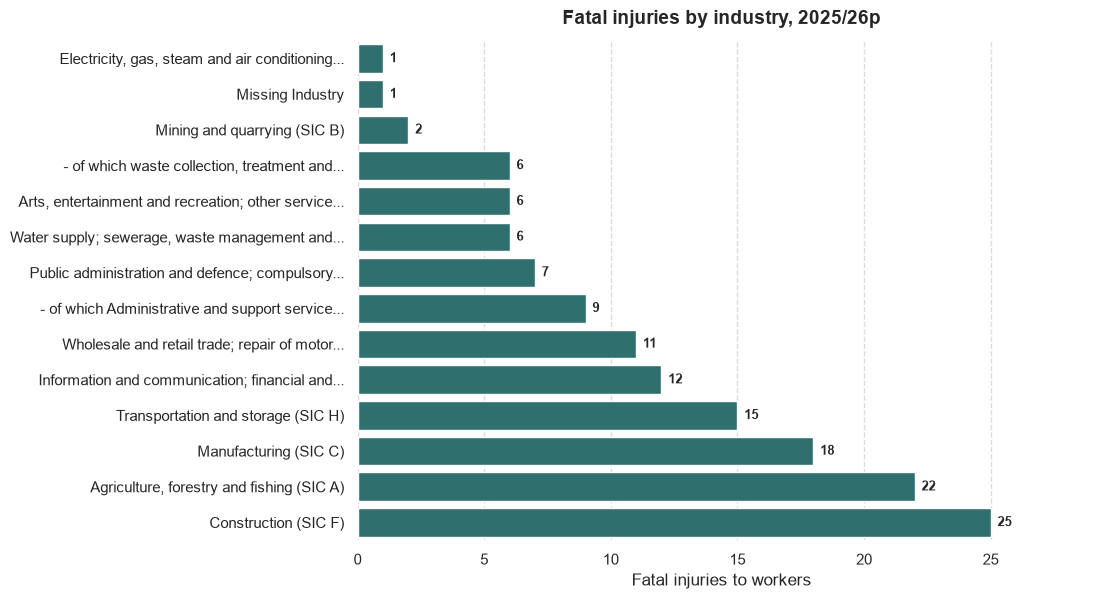

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
import textwrap

sns.set_theme(style="whitegrid")


def plot_fatality_bars(data, category_column, total_category, title, color):
    chart_data = data.loc[
        data[category_column].str.casefold() != total_category.casefold()
    ].copy()
    chart_data[category_column] = chart_data[category_column].map(
        lambda label: textwrap.shorten(
            re.sub(r"\s*\[Note[^\]]*\]", "", str(label)),
            width=52,
            placeholder="...",
        )
    )
    chart_data = chart_data.sort_values("Fatal injuries (workers)", ascending=True)

    figure_height = max(5.5, len(chart_data) * 0.43)
    fig, ax = plt.subplots(figsize=(13, figure_height))
    sns.barplot(
        data=chart_data,
        x="Fatal injuries (workers)",
        y=category_column,
        color=color,
        ax=ax,
    )

    for bar in ax.patches:
        value = bar.get_width()
        ax.annotate(
            f"{int(round(value))}",
            xy=(value, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=9,
            fontweight="bold",
        )

    max_value = chart_data["Fatal injuries (workers)"].max()
    ax.set_xlim(0, max_value * 1.15 if max_value else 1)
    ax.xaxis.grid(True, linestyle="--", alpha=0.55, color="#b8c2cc")
    ax.yaxis.grid(False)
    ax.set_axisbelow(True)
    sns.despine(left=True, bottom=True, ax=ax)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Fatal injuries to workers")
    ax.set_ylabel("")
    fig.subplots_adjust(left=0.4, right=0.96, top=0.93, bottom=0.1)
    plt.show()


# Exclude the overall total so it is not shown as a peer industry category.
plot_fatality_bars(
    industry_2025_26,
    category_column="Industry",
    total_category="All industries (SIC A-U)",
    title="Fatal injuries by industry, 2025/26p",
    color="#247b78",
)

### Fatal injuries by accident kind (2025/26p)

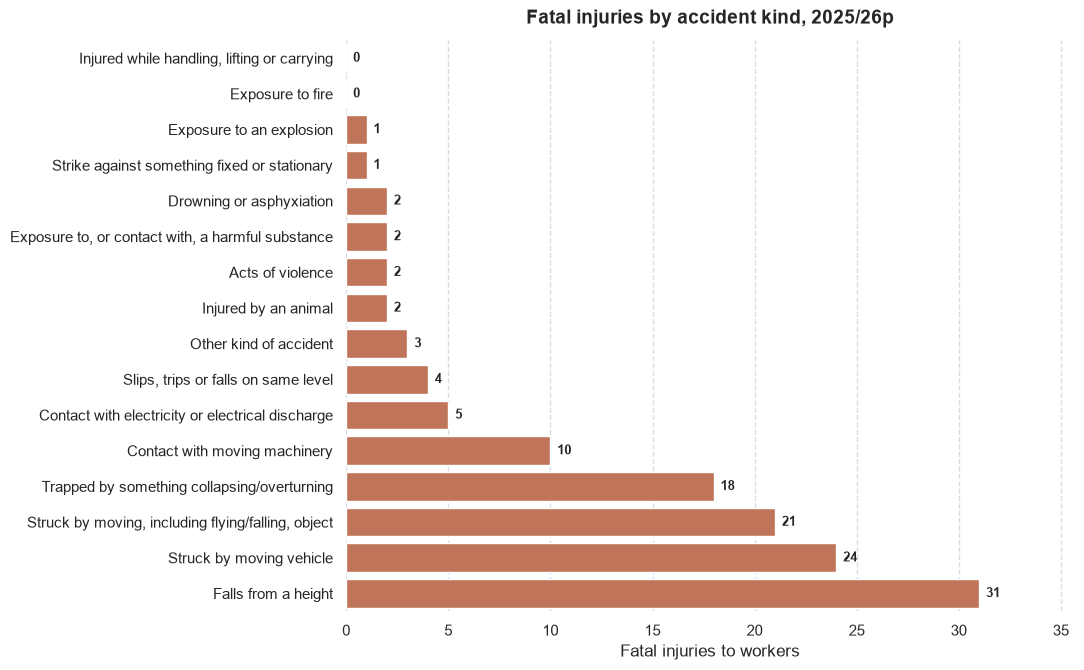

In [11]:
# Exclude the overall total so it is not shown as an accident-kind category.
plot_fatality_bars(
    accident_kind_2025_26,
    category_column="Accident kind",
    total_category="All accident kinds",
    title="Fatal injuries by accident kind, 2025/26p",
    color="#d16c48",
)

### Fatal injuries by age (2025/26p)

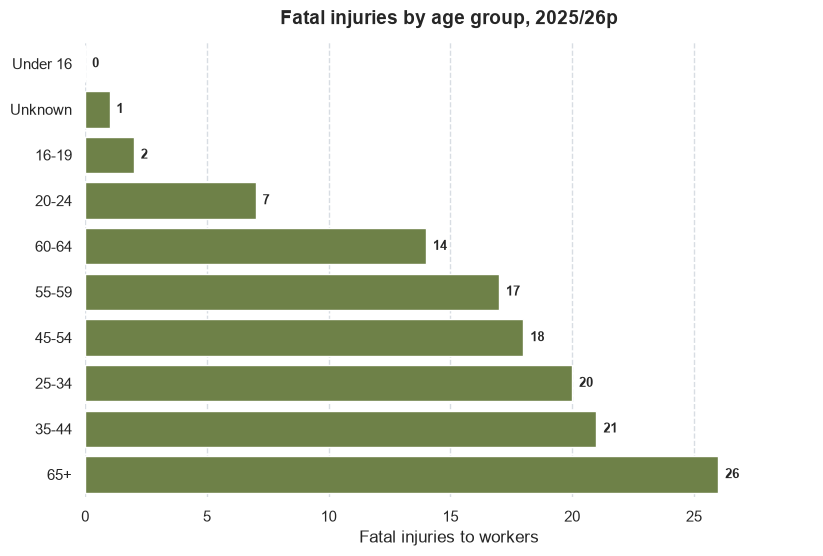

In [13]:
# The total age-group row is excluded; each remaining bar is one age group.
plot_fatality_bars(
    age_group_2025_26,
    category_column="Age group",
    total_category="All",
    title="Fatal injuries by age group, 2025/26p",
    color="#718b3e",
)

### fatalities by age in donut chart

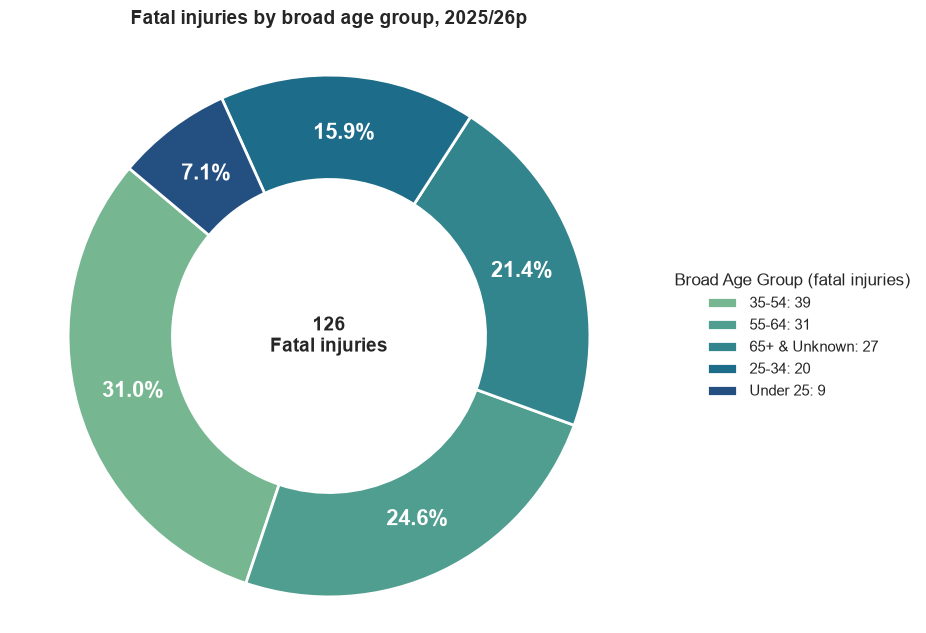

In [40]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def plot_grouped_donut(
    data, category_column, value_column, total_category, title
):
  # Robust data cleaning matching your working script
  chart_data = data.loc[
      data[category_column].astype("string").str.casefold()
      != total_category.casefold()
  ].copy()
  chart_data[value_column] = pd.to_numeric(
      chart_data[value_column], errors="coerce"
  )
  chart_data = chart_data.dropna(subset=[category_column, value_column])

  # Flexible grouping function that safely categorizes age strings
  def group_ages(cat):
    c = str(cat).casefold()
    if any(x in c for x in ["under", "16-19", "20-24", "19", "24"]) and not (
        "65" in c
    ):
      return "Under 25"
    elif "25-34" in c or "25 to 34" in c:
      return "25-34"
    elif any(x in c for x in ["35-44", "45-54", "35", "45"]):
      return "35-54"
    elif any(x in c for x in ["55-59", "60-64", "55", "60"]):
      return "55-64"
    else:
      return "65+ & Unknown"

  chart_data["Broad Group"] = chart_data[category_column].apply(group_ages)
  grouped = (
      chart_data.groupby("Broad Group")[value_column].sum().reset_index()
  )
  grouped = grouped.sort_values(value_column, ascending=False)

  total_val = int(grouped[value_column].sum())
  fig, ax = plt.subplots(figsize=(11, 7))

  wedges, _, percentages = ax.pie(
      grouped[value_column],
      labels=None,
      autopct="%1.1f%%",
      startangle=140,
      pctdistance=0.78,
      colors=sns.color_palette("crest", n_colors=len(grouped)),
      wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2},
  )

  for p in percentages:
    p.set_color("white")
    p.set_fontweight("bold")
    p.set_fontsize(16)

  ax.text(
      0,
      0,
      f"{total_val}\nFatal injuries",
      ha="center",
      va="center",
      fontsize=14,
      fontweight="bold",
  )

  legend_labels = [
      f"{cat}: {int(val)}"
      for cat, val in zip(grouped["Broad Group"], grouped[value_column])
  ]
  ax.legend(
      wedges,
      legend_labels,
      title="Broad Age Group (fatal injuries)",
      loc="center left",
      bbox_to_anchor=(1.02, 0.5),
      frameon=False,
  )

  ax.set_title(title, fontsize=14, fontweight="bold", pad=18)
  ax.axis("equal")
  fig.subplots_adjust(left=0.04, right=0.62, top=0.9, bottom=0.08)
  plt.show()


# Example usage:
plot_grouped_donut(
    age_group_2025_26,
    category_column="Age group",
    value_column="Fatal injuries (workers)",
    total_category="All",
    title="Fatal injuries by broad age group, 2025/26p",
)

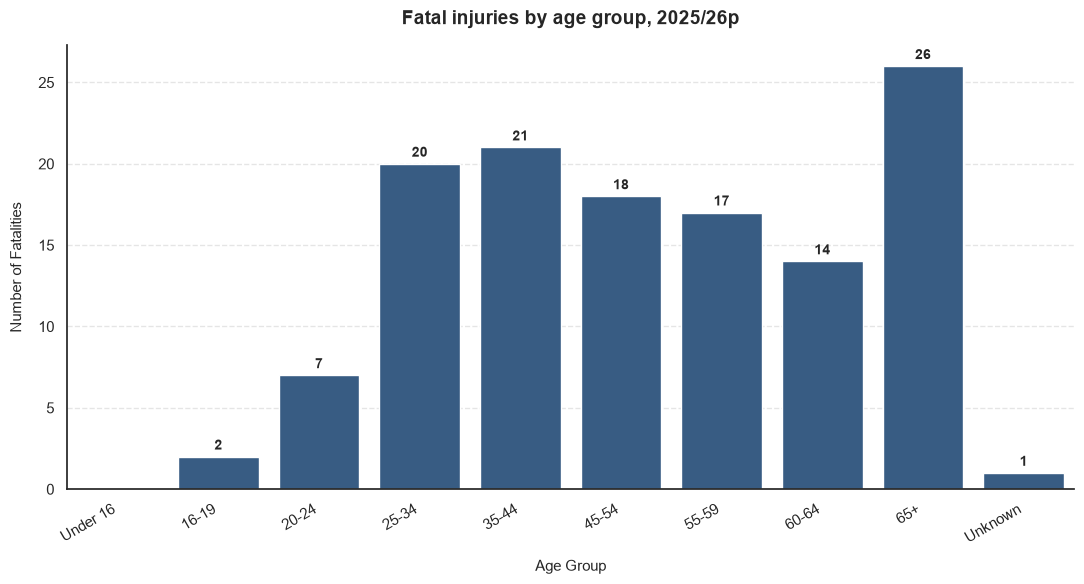

In [30]:
def plot_vertical_column(
    data, category_column, value_column, total_category, title
):
  chart_data = data.loc[
      data[category_column].astype("string").str.casefold()
      != total_category.casefold()
  ].copy()
  chart_data[value_column] = pd.to_numeric(
      chart_data[value_column], errors="coerce"
  )
  chart_data = chart_data.dropna(subset=[category_column, value_column])

  # Safe chronological ordering that adapts to available dataset categories
  age_order = [
      "Under 16",
      "16-19",
      "20-24",
      "25-34",
      "35-44",
      "45-54",
      "55-59",
      "60-64",
      "65+",
      "Unknown",
  ]
  present_cats = chart_data[category_column].tolist()
  ordered_cats = [cat for cat in age_order if cat in present_cats]
  for cat in present_cats:
    if cat not in ordered_cats:
      ordered_cats.append(cat)

  chart_data[category_column] = pd.Categorical(
      chart_data[category_column], categories=ordered_cats, ordered=True
  )
  chart_data = chart_data.sort_values(category_column)

  fig, ax = plt.subplots(figsize=(11, 6))
  sns.barplot(
      data=chart_data,
      x=category_column,
      y=value_column,
      color="#2b5c8f",
      ax=ax,
  )

  for p in ax.patches:
    height = p.get_height()
    if height > 0:
      ax.annotate(
          f"{int(height)}",
          (p.get_x() + p.get_width() / 2.0, height),
          ha="center",
          va="bottom",
          fontsize=10,
          fontweight="bold",
          xytext=(0, 3),
          textcoords="offset points",
      )

  ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
  ax.set_xlabel("Age Group", fontsize=11, labelpad=10)
  ax.set_ylabel("Number of Fatalities", fontsize=11, labelpad=10)
  plt.xticks(rotation=30, ha="right")

  sns.despine(top=True, right=True)
  ax.yaxis.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
  ax.xaxis.grid(False)

  plt.tight_layout()
  plt.show()


# Example usage:
plot_vertical_column(
    age_group_2025_26,
    category_column="Age group",
    value_column="Fatal injuries (workers)",
    total_category="All",
    title="Fatal injuries by age group, 2025/26p",
)

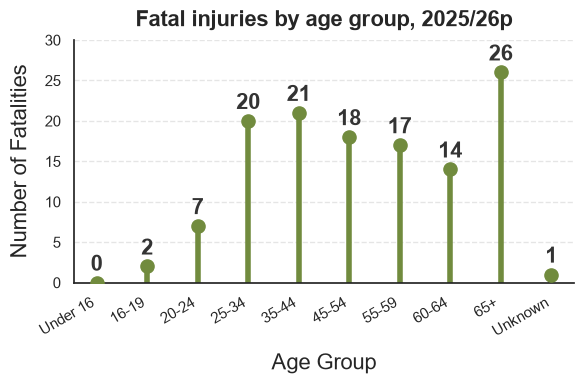

In [60]:
def plot_lollipop(data, category_column, value_column, total_category, title):
  chart_data = data.loc[
      data[category_column].astype("string").str.casefold()
      != total_category.casefold()
  ].copy()
  chart_data[value_column] = pd.to_numeric(
      chart_data[value_column], errors="coerce"
  )
  chart_data = chart_data.dropna(subset=[category_column, value_column])

  age_order = [
      "Under 16",
      "16-19",
      "20-24",
      "25-34",
      "35-44",
      "45-54",
      "55-59",
      "60-64",
      "65+",
      "Unknown",
  ]
  present_cats = chart_data[category_column].tolist()
  ordered_cats = [cat for cat in age_order if cat in present_cats]
  for cat in present_cats:
    if cat not in ordered_cats:
      ordered_cats.append(cat)

  chart_data[category_column] = pd.Categorical(
      chart_data[category_column], categories=ordered_cats, ordered=True
  )
  chart_data = chart_data.sort_values(category_column)

  fig, ax = plt.subplots(figsize=(6, 4))
  ax.vlines(
      x=chart_data[category_column],
      ymin=0,
      ymax=chart_data[value_column],
      color="#718b3e",
      linewidth=4,
  )
  ax.scatter(
      chart_data[category_column],
      chart_data[value_column],
      color="#718b3e",
      s=90,
      zorder=4,
  )

  for _, row in chart_data.iterrows():
    val = row[value_column]
    if val >= 0:
      ax.text(
          row[category_column],
          val + 0.9,
          str(int(val)),
          ha="center",
          va="bottom",
          fontsize=16,
          fontweight="bold",
          color="#333333",
      )

  ax.set_title(title, fontsize=16, fontweight="bold", pad=10)
  ax.set_xlabel("Age Group", fontsize=16, labelpad=10)
  ax.set_ylabel("Number of Fatalities", fontsize=16, labelpad=10)
  plt.xticks(rotation=30, ha="right")
  plt.ylim(0, chart_data[value_column].max() + 4)

  sns.despine(top=True, right=True)
  ax.yaxis.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
  ax.xaxis.grid(False)

  plt.tight_layout()
  plt.show()


# Example usage:
plot_lollipop(
    age_group_2025_26,
    category_column="Age group",
    value_column="Fatal injuries (workers)",
    total_category="All",
    title="Fatal injuries by age group, 2025/26p",
)

# Example structure HSE data fatal injuries in industry

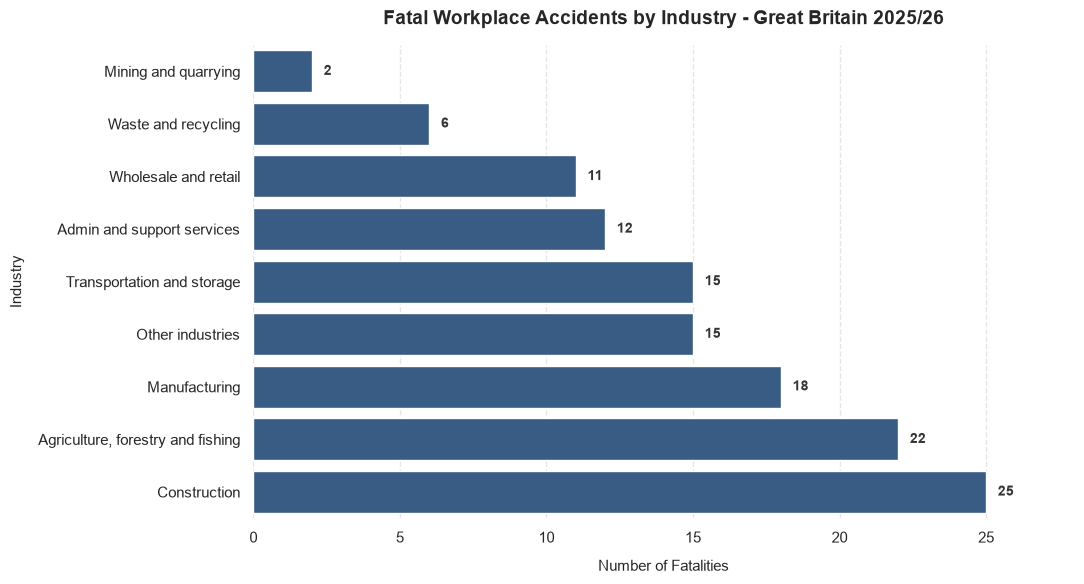

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Example structure after cleaning the HSE data
industry_data = {
    "Industry": [
        "Construction",
        "Agriculture, forestry and fishing",
        "Manufacturing",
        "Transportation and storage",
        "Admin and support services",
        "Wholesale and retail",        
        "Waste and recycling",
        "Mining and quarrying",
        "Other industries",
    ],
    "Fatalities": [25, 22, 18, 15, 12, 11, 6, 2, 15],
}

df_industry = pd.DataFrame(industry_data)

# Sort values
df_industry = df_industry.sort_values("Fatalities", ascending=True)

# Set a clean visual style
sns.set_theme(style="white")
plt.figure(figsize=(11, 6))

# Create bar chart with a professional color
ax = sns.barplot(
    data=df_industry, x="Fatalities", y="Industry", color="#2b5c8f"
)

# Add exact numbers at the end of each bar
for p in ax.patches:
  width = p.get_width()
  if width > 0:
    ax.text(
        width + 0.4,  # Slight offset to the right of the bar
        p.get_y() + p.get_height() / 2.0,  # Center vertically on the bar
        f"{int(width)}",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#333333",
    )

# Adjust x-axis limits dynamically to give room for the text labels
plt.xlim(0, df_industry["Fatalities"].max() + 3)

# Style improvements
plt.title(
    "Fatal Workplace Accidents by Industry - Great Britain 2025/26",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Number of Fatalities", fontsize=11, labelpad=10)
plt.ylabel("Industry", fontsize=11, labelpad=10)

# Clean up spines and add subtle gridlines
sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
ax.yaxis.grid(False)

plt.tight_layout()
plt.show()